In [1]:
from ecg5000 import ECG5000WindowedDataset

In [2]:
from torch.utils.data import DataLoader

In [3]:
dataset = ECG5000WindowedDataset()
data_loader = DataLoader(dataset, shuffle=True, batch_size=256)

In [4]:
import torch
import torch.optim
import torch.nn as nn

In [5]:
from ecg_lstm import ECGLSTM

In [6]:
device = torch.device("cuda")

In [7]:
model = ECGLSTM().to(device)

In [8]:
optim = torch.optim.Adam(params=model.parameters(), lr=3e-4)

In [9]:
loss = nn.MSELoss()

In [10]:
for _ in range(30):
    for batch, labels in data_loader:
        batch, labels = batch.to(device), labels.to(device)
        optim.zero_grad()
        y = model(batch)
        l = loss(y, labels)
        l.backward()
        optim.step()

In [11]:
from ecg5000 import ECG5000Dataset
import numpy as np
import matplotlib.pyplot as plt

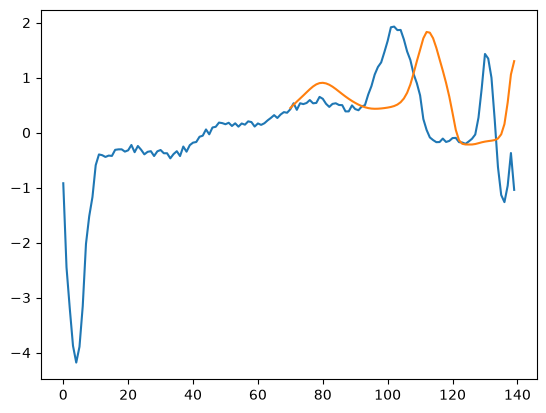

In [15]:
graph = ECG5000Dataset()[17]
x = np.arange(len(graph.squeeze()))

predict_from = 70

predicted = []

with torch.no_grad():
    window = graph[:predict_from].reshape(1, predict_from, 1).to(device)
    out, (c, h) = model._lstm(window)
    out = model._linear(out)[0, -1, 0].reshape(1, 1, 1)

    for _ in graph[predict_from:]:
        out, (c, h) = model._lstm(out, hx=(c, h))
        out = model._linear(out)
        predicted.append(out.squeeze().item())

plt.plot(x, graph)
plt.plot(np.arange(predict_from, len(graph)), predicted)